In [1]:
# 1. IMPORTS & SETUP
import os, time, copy, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import nibabel as nib
from scipy.ndimage import zoom, distance_transform_edt
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from torchvision.models import resnet18, ResNet18_Weights
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import accuracy_score, f1_score, ConfusionMatrixDisplay

SEED = 261  
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
else:
    torch.set_num_threads(6)  

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

TRAIN_DIR  = "training"
TEST_DIR   = "testing"
SPLIT_PATH = "split.json"
SAVE_PATH  = "resnet18_unet_acdc.pt"

RF_SUMMARY = {
    "Model": "Random Forest (L1)",
    "Total_Params": "200 trees",
    "Train_s": 180.0,
    "Val_Pred_s": 25.0,
    "Val_Macro_F1": 0.59,
}

Using device: cpu


In [2]:
# 2. DATA LOADING, AUDIT & PREPROCESSING 
def crop_or_pad(img, size=192):
    h, w = img.shape
    out = np.zeros((size, size), dtype=img.dtype)
    sy0, sx0 = max((h - size) // 2, 0), max((w - size) // 2, 0)
    dy0, dx0 = max((size - h) // 2, 0), max((size - w) // 2, 0)
    ch, cw = min(h, size), min(w, size)
    out[dy0:dy0 + ch, dx0:dx0 + cw] = img[sy0:sy0 + ch, sx0:sx0 + cw]
    return out

def preprocess_volume(img_3d, mask_3d, spacing_xy, target_mm=1.5, size=192):
    assert not np.isnan(img_3d).any(), "NaN values found in MRI scan!"
    lo, hi = np.percentile(img_3d, [1, 99])
    img_3d = (np.clip(img_3d, lo, hi) - lo) / (hi - lo + 1e-8)
    scale_xy = (spacing_xy[0] / target_mm, spacing_xy[1] / target_mm)

    imgs, masks, lost_px = [], [], 0
    for z in range(img_3d.shape[2]):
        sl_img = zoom(img_3d[:, :, z], scale_xy, order=1)
        sl_msk = zoom(mask_3d[:, :, z], scale_xy, order=0)
        c_msk  = crop_or_pad(sl_msk, size).astype(np.int64)
        lost_px += int((sl_msk > 0).sum() - (c_msk > 0).sum())
        imgs.append(crop_or_pad(sl_img, size).astype(np.float32))
        masks.append(c_msk)
    return np.stack(imgs), np.stack(masks), lost_px

def load_acdc_folder(root_dir):
    patients, total_lost_px = [], 0
    for pid in sorted(os.listdir(root_dir)):
        pdir = os.path.join(root_dir, pid)
        if not os.path.isdir(pdir) or not pid.startswith("patient"):
            continue
        with open(os.path.join(pdir, "Info.cfg")) as f:
            cfg = dict(line.strip().split(":", 1) for line in f if ":" in line)
        rec = {
            "id": pid, "Group": cfg["Group"].strip(),
            "ED": int(cfg["ED"]), "ES": int(cfg["ES"]),
            "Height": float(cfg["Height"]), "Weight": float(cfg["Weight"]),
        }
        assert rec["Height"] > 0 and rec["Weight"] > 0, f"Invalid metadata for {pid}"
        for phase in ["ED", "ES"]:
            fr = rec[phase]
            img_nii = nib.load(os.path.join(pdir, f"{pid}_frame{fr:02d}.nii.gz"))
            gt_nii  = nib.load(os.path.join(pdir, f"{pid}_frame{fr:02d}_gt.nii.gz"))
            zooms = img_nii.header.get_zooms()
            imgs, masks, lost = preprocess_volume(img_nii.get_fdata(), gt_nii.get_fdata(), zooms[:2])
            rec[f"{phase}_imgs"], rec[f"{phase}_masks"] = imgs, masks
            rec[f"{phase}_dz"] = float(zooms[2])
            total_lost_px += lost
        patients.append(rec)
    print(f"Loaded {len(patients)} patients from '{root_dir}' | Heart pixels lost to 192x192 crop: {total_lost_px}")
    return patients

def patients_to_tensors(patient_list):
    imgs, masks, meta = [], [], []
    for p in patient_list:
        for phase in ["ED", "ES"]:
            n = len(p[f"{phase}_imgs"])
            imgs.append(p[f"{phase}_imgs"])
            masks.append(p[f"{phase}_masks"])
            meta.extend([{
                "patient_id": p["id"],
                "group": p["Group"],
                "phase": phase,
                "z": z,
                "z_norm": z / max(n - 1, 1),
                "n_slices": n,
            } for z in range(n)])
    X = torch.tensor(np.concatenate(imgs), dtype=torch.float32).unsqueeze(1)
    y = torch.tensor(np.concatenate(masks), dtype=torch.long)
    return X, y, pd.DataFrame(meta)

with open(SPLIT_PATH, "r") as f:
    split = json.load(f)

train_ids = set(split["train"])
val_ids   = set(split["val"])

train_patients_all = load_acdc_folder(TRAIN_DIR)
train_pts = [p for p in train_patients_all if p["id"] in train_ids]
val_pts   = [p for p in train_patients_all if p["id"] in val_ids]

assert len(train_pts) == 80 and len(val_pts) == 20, "Split size mismatch!"
assert train_ids.isdisjoint(val_ids), "Patient overlap between train and val!"

Xtr, ytr, meta_tr = patients_to_tensors(train_pts)
Xva, yva, meta_va = patients_to_tensors(val_pts)
print(f"Train slices: {len(Xtr)} ({len(train_pts)} pts) | Val slices: {len(Xva)} ({len(val_pts)} pts)")

Loaded 100 patients from 'training' | Heart pixels lost to 192x192 crop: 0
Train slices: 1526 (80 pts) | Val slices: 376 (20 pts)


In [3]:
# 3. PRETRAINED RESNET18-UNET 
def dec_block(in_c, out_c, dropout=0.0):
    layers = [
        nn.Conv2d(in_c, out_c, kernel_size=3, padding=1, bias=False),
        nn.BatchNorm2d(out_c),
        nn.ReLU(inplace=True),
        nn.Conv2d(out_c, out_c, kernel_size=3, padding=1, bias=False),
        nn.BatchNorm2d(out_c),
        nn.ReLU(inplace=True),
    ]
    if dropout > 0:
        layers.append(nn.Dropout2d(p=dropout))
    return nn.Sequential(*layers)

class PretrainedResNetUNet(nn.Module):
    def __init__(self, num_classes=4, dropout=0.1):
        super().__init__()
        # imageNet normalization stats required by ResNet18_Weights.DEFAULT
        self.register_buffer("mean", torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1))
        self.register_buffer("std",  torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1))

        backbone = resnet18(weights=ResNet18_Weights.DEFAULT)
        self.stem    = nn.Sequential(backbone.conv1, backbone.bn1, backbone.relu)  # 64, 96x96
        self.maxpool = backbone.maxpool
        self.layer1  = backbone.layer1  # 64,  48x48
        self.layer2  = backbone.layer2  # 128, 24x24
        self.layer3  = backbone.layer3  # 256, 12x12
        self.layer4  = backbone.layer4  # 512,  6x6
        self.frozen_modules = []

        # bilinear upsampling + lighter BatchNorm decoder (no checkerboard artifacts)
        self.up   = nn.Upsample(scale_factor=2, mode="bilinear", align_corners=False)
        self.dec4 = dec_block(512 + 256, 128, dropout)
        self.dec3 = dec_block(128 + 128, 64,  dropout)
        self.dec2 = dec_block(64  + 64,  32,  0.0)
        self.dec1 = dec_block(32  + 64,  32,  0.0)
        self.dec0 = dec_block(32,        16,  0.0)  # no dropout right before output
        self.out  = nn.Conv2d(16, num_classes, kernel_size=1)
        self.decoder = nn.ModuleList([self.dec4, self.dec3, self.dec2, self.dec1, self.dec0, self.out])

    def set_encoder_trainable(self, unfreeze_layer4=False):
        self.frozen_modules = [self.stem, self.layer1, self.layer2, self.layer3]
        if not unfreeze_layer4:
            self.frozen_modules.append(self.layer4)
        for m in self.frozen_modules:
            for p in m.parameters():
                p.requires_grad = False
        if unfreeze_layer4:
            for p in self.layer4.parameters():
                p.requires_grad = True

    def train(self, mode=True):
        super().train(mode)
        for m in self.frozen_modules:
            m.eval()
        return self

    def forward(self, x):
        x  = (x.repeat(1, 3, 1, 1) - self.mean) / self.std
        s1 = self.stem(x)
        s2 = self.layer1(self.maxpool(s1))
        s3 = self.layer2(s2)
        s4 = self.layer3(s3)
        b  = self.layer4(s4)

        d4 = self.dec4(torch.cat([self.up(b),  s4], dim=1))
        d3 = self.dec3(torch.cat([self.up(d4), s3], dim=1))
        d2 = self.dec2(torch.cat([self.up(d3), s2], dim=1))
        d1 = self.dec1(torch.cat([self.up(d2), s1], dim=1))
        return self.out(self.dec0(self.up(d1)))

  [Quick check] ~2.0 min/epoch | Est. stage max (10 ep): 20.4 min
Epoch 01/10 | 138.5s | val_F1=0.421 (best=0.421) | Stage ETA (max): 20.8 min
Epoch 02/10 | 119.8s | val_F1=0.757 (best=0.757) | Stage ETA (max): 17.2 min
Epoch 03/10 | 120.4s | val_F1=0.810 (best=0.810) | Stage ETA (max): 14.7 min
Epoch 04/10 | 121.4s | val_F1=0.838 (best=0.838) | Stage ETA (max): 12.5 min
Epoch 05/10 | 125.9s | val_F1=0.837 (best=0.838) | Stage ETA (max): 10.4 min
Epoch 06/10 | 126.0s | val_F1=0.834 (best=0.838) | Stage ETA (max): 8.4 min
Epoch 07/10 | 115.5s | val_F1=0.880 (best=0.880) | Stage ETA (max): 6.2 min
Epoch 08/10 | 115.6s | val_F1=0.808 (best=0.880) | Stage ETA (max): 4.1 min
Epoch 09/10 | 142.2s | val_F1=0.877 (best=0.880) | Stage ETA (max): 2.1 min
Epoch 10/10 | 125.5s | val_F1=0.887 (best=0.887) | Stage ETA (max): 0.0 min
  [Quick check] ~2.1 min/epoch | Est. stage max (15 ep): 31.3 min
Epoch 01/15 | 140.4s | val_F1=0.879 (best=0.887) | Stage ETA (max): 32.8 min
Epoch 02/15 | 142.7s | val

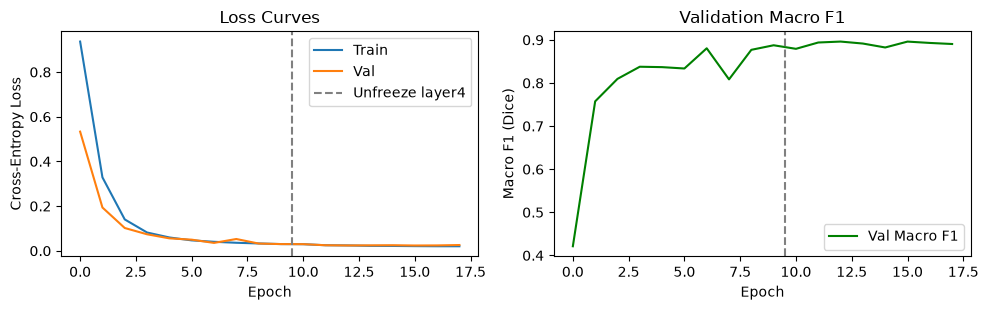

In [4]:
# 4. METRICS, AUGMENTATION & TWO-STAGE TRAINING WITH EARLY STOPPING
def seg_metrics(y_true, y_pred):
    """Per-structure Precision, Recall, F1 (Dice), and Macro F1 excluding background."""
    out, f1s = {}, []
    for c, name in {1: "RV", 2: "Myo", 3: "LV"}.items():
        tp = ((y_pred == c) & (y_true == c)).sum().item()
        fp = ((y_pred == c) & (y_true != c)).sum().item()
        fn = ((y_pred != c) & (y_true == c)).sum().item()
        out[f"{name}_P"]  = tp / (tp + fp + 1e-8)
        out[f"{name}_R"]  = tp / (tp + fn + 1e-8)
        out[f"{name}_F1"] = 2 * tp / (2 * tp + fp + fn + 1e-8)
        f1s.append(out[f"{name}_F1"])
    out["Macro_F1"] = float(np.mean(f1s))
    return out

def augment_batch(xb, yb):
    if np.random.rand() < 0.5:
        xb, yb = torch.flip(xb, [-1]), torch.flip(yb, [-1])
    if np.random.rand() < 0.5:
        xb, yb = torch.flip(xb, [-2]), torch.flip(yb, [-2])
    k = np.random.randint(0, 4)
    if k > 0:
        xb, yb = torch.rot90(xb, k, [-2, -1]), torch.rot90(yb, k, [-2, -1])
    return xb, yb

@torch.no_grad()
def predict_logits(model, X, batch_size=16):
    model.eval()
    loader = DataLoader(TensorDataset(X), batch_size=batch_size, shuffle=False)
    return torch.cat([model(xb.to(device)).cpu() for (xb,) in loader], dim=0)

def fit_stage(net, optimizer, train_loader, val_loader, max_epochs, patience, history, best):
    criterion = nn.CrossEntropyLoss()
    stale = 0
    stage_start = time.time()
    n_batches = len(train_loader)

    for ep in range(1, max_epochs + 1):
        ep_start = time.time()
        net.train()
        tr_loss = 0.0
        for b_idx, (xb, yb) in enumerate(train_loader, 1):
            xb, yb = augment_batch(xb, yb)
            xb, yb = xb.to(device), yb.to(device)
            optimizer.zero_grad()
            loss = criterion(net(xb), yb)
            loss.backward()
            optimizer.step()
            tr_loss += loss.item() * len(xb)

            # print a quick ETA after the first 10 batches of Epoch 1 
            if ep == 1 and b_idx == 10:
                est_ep_s = (time.time() - ep_start) * (n_batches / 10)
                print(
                    f"  [Quick check] ~{est_ep_s/60:.1f} min/epoch | "
                    f"Est. stage max ({max_epochs} ep): {(est_ep_s * max_epochs)/60:.1f} min",
                    flush=True
                )

        net.eval()
        va_loss, preds, trues = 0.0, [], []
        with torch.no_grad():
            for xb, yb in val_loader:
                logits = net(xb.to(device))
                va_loss += criterion(logits, yb.to(device)).item() * len(xb)
                preds.append(logits.argmax(dim=1).cpu())
                trues.append(yb)

        va_f1 = seg_metrics(torch.cat(trues), torch.cat(preds))["Macro_F1"]
        history["train"].append(tr_loss / len(train_loader.dataset))
        history["val"].append(va_loss / len(val_loader.dataset))
        history["val_f1"].append(va_f1)

        if va_f1 > best["f1"] + 1e-4:
            best["f1"], best["weights"], stale = va_f1, copy.deepcopy(net.state_dict()), 0
        else:
            stale += 1

        ep_s = time.time() - ep_start
        avg_s = (time.time() - stage_start) / ep
        eta_min = (avg_s * (max_epochs - ep)) / 60
        print(
            f"Epoch {ep:02d}/{max_epochs} | {ep_s:.1f}s | "
            f"val_F1={va_f1:.3f} (best={best['f1']:.3f}) | "
            f"Stage ETA (max): {eta_min:.1f} min",
            flush=True
        )

        if stale >= patience:
            print(f"Early stopping triggered at epoch {ep}.", flush=True)
            break

torch.manual_seed(SEED)
model = PretrainedResNetUNet(dropout=0.1).to(device)
train_loader = DataLoader(TensorDataset(Xtr, ytr), batch_size=16, shuffle=True,
                          generator=torch.Generator().manual_seed(SEED))
val_loader   = DataLoader(TensorDataset(Xva, yva), batch_size=16)

history = {"train": [], "val": [], "val_f1": []}
best = {"f1": -1.0, "weights": copy.deepcopy(model.state_dict())}
t0 = time.time()

# stage 1: freeze pretrained ResNet18 backbone, train decoder only
model.set_encoder_trainable(unfreeze_layer4=False)
opt1 = torch.optim.AdamW(model.decoder.parameters(), lr=1e-3, weight_decay=1e-4)
fit_stage(model, opt1, train_loader, val_loader, max_epochs=10, patience=4, history=history, best=best)
stage1_end = len(history["train"])

# stage 2: unfreeze layer4 and fine-tune with a smaller learning rate
model.load_state_dict(best["weights"])  # begin stage 2 with best stage 1 cp
model.set_encoder_trainable(unfreeze_layer4=True)
opt2 = torch.optim.AdamW([
    {"params": model.layer4.parameters(),  "lr": 1e-4},
    {"params": model.decoder.parameters(), "lr": 5e-4},
], weight_decay=1e-4)
fit_stage(model, opt2, train_loader, val_loader, max_epochs=15, patience=5, history=history, best=best)

train_time_s = time.time() - t0
model.load_state_dict(best["weights"])
model.eval()

t_pred = time.time()
val_logits = predict_logits(model, Xva)
val_pred_s = time.time() - t_pred
val_preds  = val_logits.argmax(dim=1)
val_res    = seg_metrics(yva, val_preds)
total_params = sum(p.numel() for p in model.parameters())
print(f"Total Params: {total_params:,} | Train Time: {train_time_s:.1f}s | Val Pred Time: {val_pred_s:.2f}s")
print("Validation Metrics:", {k: round(v, 3) for k, v in val_res.items()})

fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
ax[0].plot(history["train"], label="Train"); ax[0].plot(history["val"], label="Val")
ax[0].axvline(stage1_end - 0.5, color="gray", ls="--", label="Unfreeze layer4")
ax[0].set(xlabel="Epoch", ylabel="Cross-Entropy Loss", title="Loss Curves"); ax[0].legend()
ax[1].plot(history["val_f1"], color="green", label="Val Macro F1")
ax[1].axvline(stage1_end - 0.5, color="gray", ls="--")
ax[1].set(xlabel="Epoch", ylabel="Macro F1 (Dice)", title="Validation Macro F1"); ax[1].legend()
plt.tight_layout(); plt.show()

C:\Users\sarah\AppData\Local\Temp\ipykernel_18200\1025754626.py:6: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\torch\csrc\utils\tensor_numpy.cpp:214.)
  out["by_moment"][phase] = round(seg_metrics(y_true[idx], y_pred[idx])["Macro_F1"], 4)


Val Breakdown: {'by_moment': {'ED': 0.9039, 'ES': 0.8798}, 'by_slice_position': {'first third': 0.9052, 'middle': 0.9149, 'last third': 0.8345}, 'by_group': {'DCM': 0.8875, 'HCM': 0.8951, 'MINF': 0.8912, 'NOR': 0.9124, 'RV': 0.8795}}
Val Confidence (teammate pred>0 def): {'calibration_error': 0.0078, 'mean_conf_when_right': 0.9176, 'mean_conf_when_wrong': 0.703, 'share_right': 0.9034}
All-Pixel ECE    -> Before: 0.0009 | After (T=0.92): 0.0010
Heart-Region ECE -> Before: 0.0418 | After (T=0.92): 0.0527


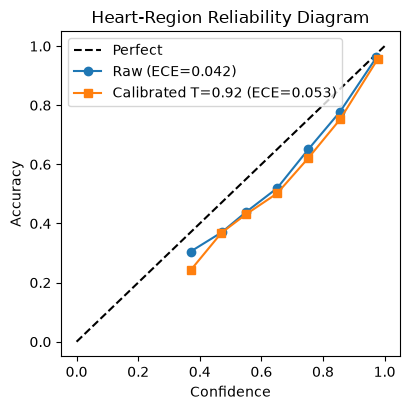

In [5]:
# 5. FAILURE ANALYSIS & CALIBRATION
def breakdown_metrics(y_true, y_pred, meta_df):
    out = {"by_moment": {}, "by_slice_position": {}, "by_group": {}}
    for phase in ["ED", "ES"]:
        idx = (meta_df["phase"] == phase).to_numpy()
        out["by_moment"][phase] = round(seg_metrics(y_true[idx], y_pred[idx])["Macro_F1"], 4)

    pos_labels = np.where(
        meta_df["z_norm"] < 1 / 3, "first third",
        np.where(meta_df["z_norm"] < 2 / 3, "middle", "last third")
    )
    for pos in ["first third", "middle", "last third"]:
        idx = (pos_labels == pos)
        out["by_slice_position"][pos] = round(seg_metrics(y_true[idx], y_pred[idx])["Macro_F1"], 4)

    for g in sorted(meta_df["group"].unique()):
        idx = (meta_df["group"] == g).to_numpy()
        out["by_group"][g] = round(seg_metrics(y_true[idx], y_pred[idx])["Macro_F1"], 4)
    return out

def teammate_confidence(logits, y_true, batch_size=32):
    """Exact same ECE & confidence definition as teammate (pixels predicted as heart: pred > 0)."""
    confs_all, right_all = [], []
    for i in range(0, len(logits), batch_size):
        probs = torch.softmax(logits[i:i + batch_size], dim=1)
        confs, preds = probs.max(dim=1)
        keep = preds > 0
        if keep.any():
            confs_all.append(confs[keep].numpy())
            right_all.append((preds[keep] == y_true[i:i + batch_size][keep]).numpy())
    c = np.concatenate(confs_all)
    r = np.concatenate(right_all)
    bins = np.minimum((c * 10).astype(int), 9)
    ece = sum(
        abs(c[bins == b].mean() - r[bins == b].mean()) * (bins == b).mean()
        for b in range(10) if (bins == b).any()
    )
    return dict(
        calibration_error=round(float(ece), 4),
        mean_conf_when_right=round(float(c[r].mean()), 4),
        mean_conf_when_wrong=round(float(c[~r].mean()), 4) if (~r).any() else None,
        share_right=round(float(r.mean()), 4),
    )

val_breakdown = breakdown_metrics(yva, val_preds, meta_va)
print("Val Breakdown:", val_breakdown)
print("Val Confidence (teammate pred>0 def):", teammate_confidence(val_logits, yva))

# reliability diagram & temperature scaling 
def ece_and_bins(probs, targets, n_bins=10):
    confs, preds = probs.max(dim=1)
    accs = (preds == targets).float()
    ece, bc, ba = 0.0, [], []
    bins = torch.linspace(0, 1, n_bins + 1)
    for lo, hi in zip(bins[:-1], bins[1:]):
        m = (confs > lo) & (confs <= hi)
        if m.sum() > 0:
            ece += m.float().mean().item() * abs(accs[m].mean().item() - confs[m].mean().item())
            bc.append(confs[m].mean().item())
            ba.append(accs[m].mean().item())
    return ece, bc, ba

flat_logits = val_logits.permute(0, 2, 3, 1).reshape(-1, 4)[::20]
flat_true   = yva.reshape(-1)[::20]
heart_mask  = (flat_true > 0) | (flat_logits.argmax(dim=1) > 0)

log_T = torch.zeros(1, requires_grad=True)
t_opt = torch.optim.Adam([log_T], lr=0.05)
for _ in range(100):
    t_opt.zero_grad()
    nn.CrossEntropyLoss()(flat_logits / torch.exp(log_T), flat_true).backward()
    t_opt.step()
T_opt = torch.exp(log_T).item()

p_raw = torch.softmax(flat_logits, dim=1)
p_cal = torch.softmax(flat_logits / T_opt, dim=1)
ece_all_raw, _, _ = ece_and_bins(p_raw, flat_true)
ece_all_cal, _, _ = ece_and_bins(p_cal, flat_true)
ece_h_raw, bc1, ba1 = ece_and_bins(p_raw[heart_mask], flat_true[heart_mask])
ece_h_cal, bc2, ba2 = ece_and_bins(p_cal[heart_mask], flat_true[heart_mask])

print(f"All-Pixel ECE    -> Before: {ece_all_raw:.4f} | After (T={T_opt:.2f}): {ece_all_cal:.4f}")
print(f"Heart-Region ECE -> Before: {ece_h_raw:.4f} | After (T={T_opt:.2f}): {ece_h_cal:.4f}")

plt.figure(figsize=(4.2, 4.2))
plt.plot([0, 1], [0, 1], "k--", label="Perfect")
plt.plot(bc1, ba1, "o-", label=f"Raw (ECE={ece_h_raw:.3f})")
plt.plot(bc2, ba2, "s-", label=f"Calibrated T={T_opt:.2f} (ECE={ece_h_cal:.3f})")
plt.xlabel("Confidence"); plt.ylabel("Accuracy"); plt.title("Heart-Region Reliability Diagram")
plt.legend(); plt.tight_layout(); plt.show()

[Expert Outlines] LR (C=0.1) -> Acc: 0.950, F1: 0.949 | GB -> Acc: 0.950, F1: 0.949
[ResNet18-UNet Outlines] LR (C=0.1) -> Acc: 0.950, F1: 0.949 | GB -> Acc: 0.900, F1: 0.898


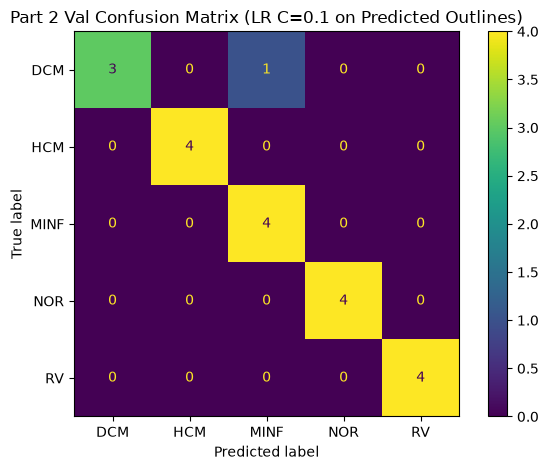

In [6]:
# 6. PART 2 DIAGNOSIS: EXPERT vs. PREDICTED OUTLINES
def extract_12_features(m_ed, m_es, dz_ed, dz_es, height_cm, weight_kg, pixel_mm=1.5):
    v_ed = (pixel_mm ** 2 * dz_ed) / 1000.0
    v_es = (pixel_mm ** 2 * dz_es) / 1000.0

    lv_edv, lv_esv = (m_ed == 3).sum() * v_ed, (m_es == 3).sum() * v_es
    rv_edv, rv_esv = (m_ed == 1).sum() * v_ed, (m_es == 1).sum() * v_es
    muscle_mass    = (m_ed == 2).sum() * v_ed * 1.05

    lv_ef = (lv_edv - lv_esv) / max(lv_edv, 1e-6)
    rv_ef = (rv_edv - rv_esv) / max(rv_edv, 1e-6)

    bsa = np.sqrt((height_cm * weight_kg) / 3600.0)
    max_thickness = max(
        (2.0 * distance_transform_edt(sl == 2, sampling=(pixel_mm, pixel_mm)).max() for sl in m_ed),
        default=0.0
    )

    return [
        lv_edv, lv_esv, lv_ef,
        rv_edv, rv_esv, rv_ef,
        muscle_mass,
        lv_edv / bsa, rv_edv / bsa, muscle_mass / bsa,
        rv_edv / max(lv_edv, 1e-6),
        max_thickness,
    ]

def build_diag_data(patient_list, seg_model=None):
    X_rows, y_rows = [], []
    for p in patient_list:
        if seg_model is None:
            m_ed, m_es = p["ED_masks"], p["ES_masks"]
        else:
            ed_t = torch.tensor(p["ED_imgs"]).unsqueeze(1)
            es_t = torch.tensor(p["ES_imgs"]).unsqueeze(1)
            m_ed = predict_logits(seg_model, ed_t).argmax(dim=1).numpy()
            m_es = predict_logits(seg_model, es_t).argmax(dim=1).numpy()
        X_rows.append(extract_12_features(
            m_ed, m_es, p["ED_dz"], p["ES_dz"], p["Height"], p["Weight"]
        ))
        y_rows.append(p["Group"])
    return np.array(X_rows, dtype=np.float32), np.array(y_rows)

X_d_tr, y_d_tr    = build_diag_data(train_pts, seg_model=None)
X_d_va_gt, y_d_va = build_diag_data(val_pts, seg_model=None)
X_d_va_pr, _      = build_diag_data(val_pts, seg_model=model)

scaler = StandardScaler().fit(X_d_tr)
lr_clf = LogisticRegression(C=0.1, max_iter=5000, random_state=SEED).fit(scaler.transform(X_d_tr), y_d_tr)
gb_clf = GradientBoostingClassifier(
    n_estimators=100, max_depth=2, learning_rate=0.05, subsample=0.8, random_state=SEED
).fit(X_d_tr, y_d_tr)

for label, X_eval in [("Expert Outlines", X_d_va_gt), ("ResNet18-UNet Outlines", X_d_va_pr)]:
    p_lr = lr_clf.predict(scaler.transform(X_eval))
    p_gb = gb_clf.predict(X_eval)
    print(f"[{label}] LR (C=0.1) -> Acc: {accuracy_score(y_d_va, p_lr):.3f}, F1: {f1_score(y_d_va, p_lr, average='macro'):.3f} | "
          f"GB -> Acc: {accuracy_score(y_d_va, p_gb):.3f}, F1: {f1_score(y_d_va, p_gb, average='macro'):.3f}")

ConfusionMatrixDisplay.from_predictions(y_d_va, lr_clf.predict(scaler.transform(X_d_va_pr)))
plt.title("Part 2 Val Confusion Matrix (LR C=0.1 on Predicted Outlines)")
plt.tight_layout(); plt.show()

In [7]:
# 7. COMPLEXITY TABLE & ONE-TIME TEST EVALUATION + SAVE MODEL 
print(pd.DataFrame([
    RF_SUMMARY,
    {
        "Model": "ResNet18-UNet (L2)",
        "Total_Params": f"{total_params:,}",
        "Train_s": round(train_time_s, 1),
        "Val_Pred_s": round(val_pred_s, 2),
        "Val_Macro_F1": round(val_res["Macro_F1"], 3),
    }
]).to_string(index=False))

RUN_FINAL_TEST = True 

if RUN_FINAL_TEST:
    torch.save(model.state_dict(), SAVE_PATH)
    print("Saved model weights to:", SAVE_PATH)

    test_pts = load_acdc_folder(TEST_DIR)
    Xte, yte, meta_te = patients_to_tensors(test_pts)

    # predict once on all 50 test patients
    t0 = time.time()
    te_logits = predict_logits(model, Xte)
    te_pred_s = time.time() - t0
    te_preds  = te_logits.argmax(dim=1)

    te_seg = seg_metrics(yte, te_preds)
    te_brk = breakdown_metrics(yte, te_preds, meta_te)
    te_conf = teammate_confidence(te_logits, yte)

    print("FINAL TEST Segmentation:", {k: round(v, 4) for k, v in te_seg.items()})
    print(f"FINAL TEST Speed: {te_pred_s:.2f}s total | {te_pred_s / len(Xte):.4f} s/slice")
    print("FINAL TEST Breakdown:", te_brk)
    print("FINAL TEST Confidence (teammate pred>0 def):", te_conf)

    X_dev_d, y_dev_d = build_diag_data(train_patients_all, seg_model=None)
    X_te_gt, y_te_d  = build_diag_data(test_pts, seg_model=None)

    X_te_pr_rows, pos = [], 0
    for p in test_pts:
        n_ed = len(p["ED_imgs"])
        m_ed = te_preds[pos : pos + n_ed].numpy()
        pos += n_ed
        n_es = len(p["ES_imgs"])
        m_es = te_preds[pos : pos + n_es].numpy()
        pos += n_es
        X_te_pr_rows.append(extract_12_features(
            m_ed, m_es, p["ED_dz"], p["ES_dz"], p["Height"], p["Weight"]
        ))
    X_te_pr = np.array(X_te_pr_rows, dtype=np.float32)

    # refit Part 2 classifiers on all 100 training patients
    final_scaler = StandardScaler().fit(X_dev_d)
    final_lr = LogisticRegression(C=0.1, max_iter=5000, random_state=SEED).fit(
        final_scaler.transform(X_dev_d), y_dev_d
    )
    final_gb = GradientBoostingClassifier(
        n_estimators=100, max_depth=2, learning_rate=0.05, subsample=0.8, random_state=SEED
    ).fit(X_dev_d, y_dev_d)

    for src, X_eval in [("Expert Outlines", X_te_gt), ("ResNet18-UNet Outlines", X_te_pr)]:
        p_lr = final_lr.predict(final_scaler.transform(X_eval))
        p_gb = final_gb.predict(X_eval)
        print(f"FINAL TEST Part 2 [{src}] LR (C=0.1) -> Acc: {accuracy_score(y_te_d, p_lr):.3f}, "
              f"F1: {f1_score(y_te_d, p_lr, average='macro'):.3f} | "
              f"GB -> Acc: {accuracy_score(y_te_d, p_gb):.3f}, "
              f"F1: {f1_score(y_te_d, p_gb, average='macro'):.3f}")

    err = lambda j: round(float(np.mean(np.abs(X_te_pr[:, j] - X_te_gt[:, j]))), 3)
    mae_dict = dict(
        lv_ef_points=round(100 * err(2), 1),
        rv_ef_points=round(100 * err(5), 1),
        lv_edv_ml=err(0),
        rv_edv_ml=err(3),
    )
    print("FINAL TEST Measurement MAE (ResNet18 vs Expert):", mae_dict)

    # save verified JSON summary
    summary_json = dict(
        seed=SEED,
        parameters=int(total_params),
        train_seconds=round(train_time_s, 1),
        val_pred_seconds=round(val_pred_s, 2),
        test_seconds_per_slice=round(te_pred_s / len(Xte), 4),
        val_segmentation={k: round(v, 4) for k, v in val_res.items()},
        val_breakdown=val_breakdown,
        test_segmentation={k: round(v, 4) for k, v in te_seg.items()},
        test_breakdown=te_brk,
        test_confidence=te_conf,
        test_mae=mae_dict,
    )
    with open("resnet18_results.json", "w") as f:
        json.dump(summary_json, f, indent=2)
    print("Saved summary to resnet18_results.json")

             Model Total_Params  Train_s  Val_Pred_s  Val_Macro_F1
Random Forest (L1)    200 trees    180.0       25.00         0.590
ResNet18-UNet (L2)   12,484,036   2352.0       13.38         0.896
Saved model weights to: resnet18_unet_acdc.pt
Loaded 50 patients from 'testing' | Heart pixels lost to 192x192 crop: 0
FINAL TEST Segmentation: {'RV_P': 0.9049, 'RV_R': 0.8612, 'RV_F1': 0.8825, 'Myo_P': 0.8401, 'Myo_R': 0.8686, 'Myo_F1': 0.8541, 'LV_P': 0.9453, 'LV_R': 0.9287, 'LV_F1': 0.9369, 'Macro_F1': 0.8912}
FINAL TEST Speed: 38.77s total | 0.0360 s/slice
FINAL TEST Breakdown: {'by_moment': {'ED': 0.8998, 'ES': 0.8728}, 'by_slice_position': {'first third': 0.8884, 'middle': 0.9146, 'last third': 0.8538}, 'by_group': {'DCM': 0.8931, 'HCM': 0.8712, 'MINF': 0.8914, 'NOR': 0.9001, 'RV': 0.8857}}
FINAL TEST Confidence (teammate pred>0 def): {'calibration_error': 0.0077, 'mean_conf_when_right': 0.9159, 'mean_conf_when_wrong': 0.7016, 'share_right': 0.8966}
FINAL TEST Part 2 [Expert Outline